A CNN based disease detection for plants.Plant disease detection using CNN and ResNet.

## Project Overview

The aim of this project is to explore the image classification to recognize these plant diseases using the color-image dataset PlantVillage.

The goal is to compare the performance of a CNN model trained from scratch with a pretrained ResNet-18 model and to explore whether data augmentation during CNN training improves classification.

### Research Questions

What is the accuracy of CNN trained from scratch for plant disease classification?
2. Does the pretrained ResNet-18 differ from CNN baseline?
3) Is the effect of random horizontal flipping and rotation helpful for ResNet-18?

### Evaluation

The experiments will involve using accuracy, macro-averaged precision, macro-averaged recall and macro-averaged F1-score. Failure analysis will be assisted by the use of confusion matrices and misclassified images.



**Markdown: environment setup**

In [10]:
import torch
import torchvision
import sklearn
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Scikit-learn: 1.6.1
Pandas: 2.2.3
GPU available: True
GPU: Tesla T4


**dataset acquisition**

In [2]:
import os
import zipfile
from huggingface_hub import hf_hub_download

zip_path = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="data.zip",
    repo_type="dataset"
)

print("Downloaded archive:", zip_path)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive_names = archive.namelist()

print("Total archive entries:", len(archive_names))
print("\nFirst 20 paths:")

for path in archive_names[:20]:
    print(path)

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Downloaded archive: /root/.cache/huggingface/hub/datasets--mohanty--PlantVillage/snapshots/9e97599868962bd0079b8db4b7f1efa9185fa1e7/data.zip
Total archive entries: 163034

First 20 paths:
raw/
raw/color/
raw/color/Raspberry___healthy/
raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG
raw/color/Raspberry___healthy/d1387960-14d6-4654-ad5c-b92afa86ff6a___Mary_HL 9262.JPG
raw/color/Raspberry___healthy/fafac0a9-e5ba-420d-9dbe-034942f845b9___Mary_HL 9201.JPG
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/fe1c1683-06cc-49c5-b86a-a41fb36f058b___Mary_HL 6249.JPG
raw/color/Raspberry___healthy/e621e3c3-842a-4489-b931-89f05c254cbe___Mary_HL 9347.JPG
raw/color/Raspberry___healthy/b8a96dea-8442-4855-9fdf-c29c9d4eca5a___Mary_HL 6398.JPG
raw/color/Raspberry___healthy/42428dcc-fefc-46dd-b209-150fbeaf4862___Mary_HL 6397.JPG
raw/color/Raspberry___healthy/076d909d-cfca-47ce-a8d1-479bb77c4bab___Mary_HL 

**count images by class**

In [3]:
from collections import Counter

class_counts = Counter()

for path in archive_names:
    parts = path.split("/")

    if (
        len(parts) >= 4
        and parts[0] == "raw"
        and parts[1] == "color"
        and path.lower().endswith((".jpg", ".jpeg", ".png"))
    ):
        class_counts[parts[2]] += 1

print("Number of classes:", len(class_counts))
print("Total color images:", sum(class_counts.values()))

print("\nImages per class:")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

print("\nOfficial split files:")

for path in archive_names:
    if path.startswith("splits/") and path.endswith(".txt"):
        print(path)

Number of classes: 38
Total color images: 54305

Images per class:
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1478
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5090
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
T

**load official split files**

In [4]:
from huggingface_hub import hf_hub_download

train_file = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="splits/color_train.txt",
    repo_type="dataset"
)

test_file = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="splits/color_test.txt",
    repo_type="dataset"
)

with open(train_file, "r") as f:
    official_train = [line.strip() for line in f if line.strip()]

with open(test_file, "r") as f:
    official_test = [line.strip() for line in f if line.strip()]

print("Official training entries:", len(official_train))
print("Official test entries:", len(official_test))

print("\nTraining examples:")
for path in official_train[:5]:
    print(path)

print("\nTest examples:")
for path in official_test[:5]:
    print(path)

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

Official training entries: 43596
Official test entries: 10709

Training examples:
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL 9160.JPG
raw/color/Raspberry___healthy/98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL 9159.JPG
raw/color/Raspberry___healthy/e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL 9163.JPG
raw/color/Raspberry___healthy/de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL 9154.JPG

Test examples:
raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG
raw/color/Raspberry___healthy/8e8297fd-5e23-44f2-be98-92f7b8908f81___Mary_HL 6315.JPG
raw/color/Raspberry___healthy/67cff824-a58b-40c3-93a2-7dead429b1f0___Mary_HL 6322.JPG
raw/color/Raspberry___healthy/d20b63ce-4849-4c33-960e-74ac2ddb048c___Mary_HL 6319.JPG
raw/color/Raspberry___healthy/da1c2dba-b75e-4052-bf97-16e66fea830a___Mary_HL 6320.JPG


**validate splits and create validation data**

In [5]:
from sklearn.model_selection import train_test_split

SEED = 42

# Check for duplicate entries.
assert len(official_train) == len(set(official_train))
assert len(official_test) == len(set(official_test))

# Confirm the official training and test sets do not overlap.
assert set(official_train).isdisjoint(official_test)

# Confirm every split path exists in the downloaded archive.
archive_path_set = set(archive_names)

missing_train = [
    path for path in official_train
    if path not in archive_path_set
]

missing_test = [
    path for path in official_test
    if path not in archive_path_set
]

print("Missing training paths:", len(missing_train))
print("Missing test paths:", len(missing_test))

assert not missing_train
assert not missing_test

# Stratified validation split from official training examples.
labels = [path.split("/")[2] for path in official_train]

train_paths, val_paths = train_test_split(
    official_train,
    test_size=0.10,
    random_state=SEED,
    stratify=labels
)

train_labels = [path.split("/")[2] for path in train_paths]
val_labels = [path.split("/")[2] for path in val_paths]
test_labels = [path.split("/")[2] for path in official_test]

print("\nFinal split sizes")
print("Training:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(official_test))

print("\nNumber of classes")
print("Training:", len(set(train_labels)))
print("Validation:", len(set(val_labels)))
print("Test:", len(set(test_labels)))

# Check for leakage across all three splits.
assert set(train_paths).isdisjoint(val_paths)
assert set(train_paths).isdisjoint(official_test)
assert set(val_paths).isdisjoint(official_test)

assert set(train_labels) == set(val_labels) == set(test_labels)

print("\nSplit validation passed.")

Missing training paths: 0
Missing test paths: 0

Final split sizes
Training: 39236
Validation: 4360
Test: 10709

Number of classes
Training: 38
Validation: 38
Test: 38

Split validation passed.


**Code: transformations and class mapping**

In [6]:
import io
import random
import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

class_names = sorted(set(train_labels))
class_to_idx = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

print("Number of classes:", len(class_names))
print("\nClass-to-index examples:")

for class_name in class_names[:10]:
    print(class_name, "->", class_to_idx[class_name])

IMAGE_SIZE = 224

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

print("\nImage size:", IMAGE_SIZE)
print("Training augmentation: horizontal flip and rotation")
print("Validation/test augmentation: none")

Number of classes: 38

Class-to-index examples:
Apple___Apple_scab -> 0
Apple___Black_rot -> 1
Apple___Cedar_apple_rust -> 2
Apple___healthy -> 3
Blueberry___healthy -> 4
Cherry_(including_sour)___Powdery_mildew -> 5
Cherry_(including_sour)___healthy -> 6
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot -> 7
Corn_(maize)___Common_rust_ -> 8
Corn_(maize)___Northern_Leaf_Blight -> 9

Image size: 224
Training augmentation: horizontal flip and rotation
Validation/test augmentation: none


**optimized dataset class**

In [7]:
class PlantVillageDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform
        self._archive = None

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        if self._archive is None:
            self._archive = zipfile.ZipFile(zip_path, "r")

        path = self.paths[index]
        label_name = path.split("/")[2]

        image_bytes = self._archive.read(path)

        with Image.open(io.BytesIO(image_bytes)) as image:
            image = image.convert("RGB")
            image_tensor = self.transform(image)

        label = class_to_idx[label_name]

        return image_tensor, label

**create datasets and DataLoaders**

In [8]:
BATCH_SIZE = 8

train_dataset = PlantVillageDataset(
    train_paths,
    train_transform
)

val_dataset = PlantVillageDataset(
    val_paths,
    eval_transform
)

test_dataset = PlantVillageDataset(
    official_test,
    eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Batch size:", BATCH_SIZE)

Training images: 39236
Validation images: 4360
Test images: 10709
Number of classes: 38
Batch size: 8


**test image loading**

In [9]:
# Test one individual image.
image_tensor, label_idx = train_dataset[0]

print("Single image shape:", tuple(image_tensor.shape))
print("Label index:", label_idx)
print("Class name:", class_names[label_idx])
print("Tensor dtype:", image_tensor.dtype)
print("All values finite:", torch.isfinite(image_tensor).all().item())

# Test one batch.
images, labels = next(iter(train_loader))

print("\nBatch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Labels in batch:", labels.tolist())

assert images.shape == (
    BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE
)

assert labels.shape == (BATCH_SIZE,)
assert torch.isfinite(images).all()

assert set(train_paths).isdisjoint(val_paths)
assert set(train_paths).isdisjoint(official_test)
assert set(val_paths).isdisjoint(official_test)

print("\nAll dataset and image-loading checks passed.")

Single image shape: (3, 224, 224)
Label index: 24
Class name: Soybean___healthy
Tensor dtype: torch.float32
All values finite: True

Batch image shape: (8, 3, 224, 224)
Batch label shape: (8,)
Labels in batch: [24, 35, 15, 33, 15, 15, 30, 21]

All dataset and image-loading checks passed.


In [11]:
print("Classes:", len(class_names))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

Classes: 38
Training batches: 4905
Validation batches: 545
Test batches: 1339
Device: cuda


**CNN baseline architecture**

In [12]:

import torch
import torch.nn as nn

class PlantDiseaseCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = PlantDiseaseCNN(
    num_classes=len(class_names)
).to(device)

print("Device:", device)
print("Number of classes:", len(class_names))
print(model)


Device: cuda
Number of classes: 38
PlantDiseaseCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=256, out_features=38, bias=True)
  )
)


**CNN Training Configuration**
The CNN will be trained using the training dataset and evaluated on the validation dataset after each epoch. Cross-entropy loss is appropriate for this multi-class classification task because each image belongs to one of 38 classes. The Adam optimizer will update the model parameters to reduce classification loss.

**configure the loss function and optimizer**

In [13]:

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 3

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", num_epochs)


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Epochs: 3


**CNN training and validation**

In [14]:

import time

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    start_time = time.time()

    # 1. Training phase
    model.train()
    total_train_loss = 0.0
    train_samples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_train_loss += loss.item() * batch_size
        train_samples += batch_size

    train_loss = total_train_loss / train_samples

    # 2. Validation phase
    model.eval()
    total_val_loss = 0.0
    correct = 0
    val_samples = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = images.size(0)
            total_val_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            val_samples += batch_size

    val_loss = total_val_loss / val_samples
    val_accuracy = correct / val_samples

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Accuracy: {val_accuracy:.2%} "
        f"| Time: {elapsed / 60:.1f} min"
    )


Epoch [1/3] | Train Loss: 1.5788 | Val Loss: 0.7766 | Val Accuracy: 76.67% | Time: 3.4 min
Epoch [2/3] | Train Loss: 0.7402 | Val Loss: 0.4615 | Val Accuracy: 86.67% | Time: 3.4 min
Epoch [3/3] | Train Loss: 0.5213 | Val Loss: 0.3144 | Val Accuracy: 90.50% | Time: 3.4 min


**Training Results and Model Checkpoint**


Changes in training loss, validation loss and validation accuracy over epochs are plotted in the training history.

**Saving the model and history**

Model saved: models/cnn_baseline.pth
History saved: results/cnn_training_history.json


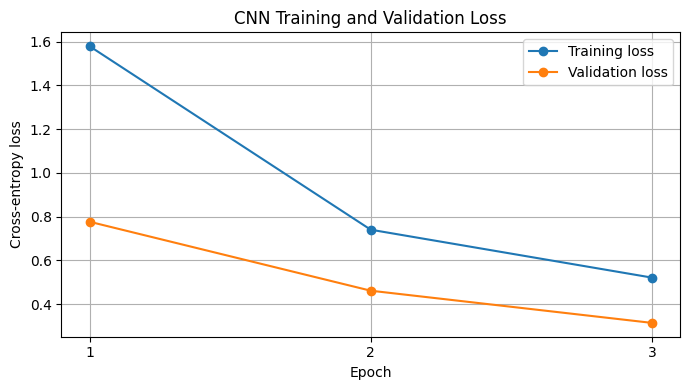

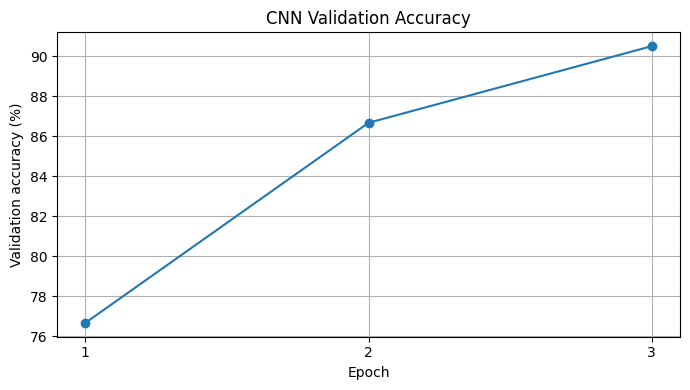

Training plots saved in results/.


In [15]:

import os
import json
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Save trained model weights and training configuration
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "num_classes": len(class_names),
        "class_names": class_names,
        "epochs": num_epochs,
        "learning_rate": optimizer.param_groups[0]["lr"]
    },
    "models/cnn_baseline.pth"
)

# Save training history
with open("results/cnn_training_history.json", "w") as f:
    json.dump(history, f, indent=2)

print("Model saved: models/cnn_baseline.pth")
print("History saved: results/cnn_training_history.json")

# Plot training and validation loss
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CNN Training and Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/cnn_loss_curves.png", dpi=150)
plt.show()

# Plot validation accuracy
plt.figure(figsize=(7, 4))
plt.plot(
    epochs,
    [value * 100 for value in history["val_accuracy"]],
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("CNN Validation Accuracy")
plt.xticks(list(epochs))
plt.grid(True)
plt.tight_layout()
plt.savefig("results/cnn_validation_accuracy.png", dpi=150)
plt.show()

print("Training plots saved in results/.")


**CNN Evaluation on the Held-Out Test Set**

The performance of the trained CNN is measured on the held-out test set from the official dataset to see how well the CNN performs on unseen images. For each of the 38 classes of plant disease and healthy plants, we report the accuracy, macro-precision, macro-recall, and macro-F1. The test set is only for the last stage evaluation, and is not utilized for training or model selection.

In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print(f"Test Accuracy:   {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall:    {test_recall:.4f}")
print(f"Macro F1-score:  {test_f1:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


Test Accuracy:   0.9003
Macro Precision: 0.8884
Macro Recall:    0.8762
Macro F1-score:  0.8783

Per-class classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.72      0.69      0.70       127
                                 Apple___Black_rot       1.00      0.84      0.91       146
                          Apple___Cedar_apple_rust       1.00      0.88      0.94        52
                                   Apple___healthy       0.93      0.68      0.78       286
                               Blueberry___healthy       0.90      0.92      0.91       324
          Cherry_(including_sour)___Powdery_mildew       0.83      0.89      0.86       219
                 Cherry_(including_sour)___healthy       0.93      0.90      0.92       123
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.57      0.89      0.69       107
                       Corn_(maize)___Com

**CNN Confusion Matrix**

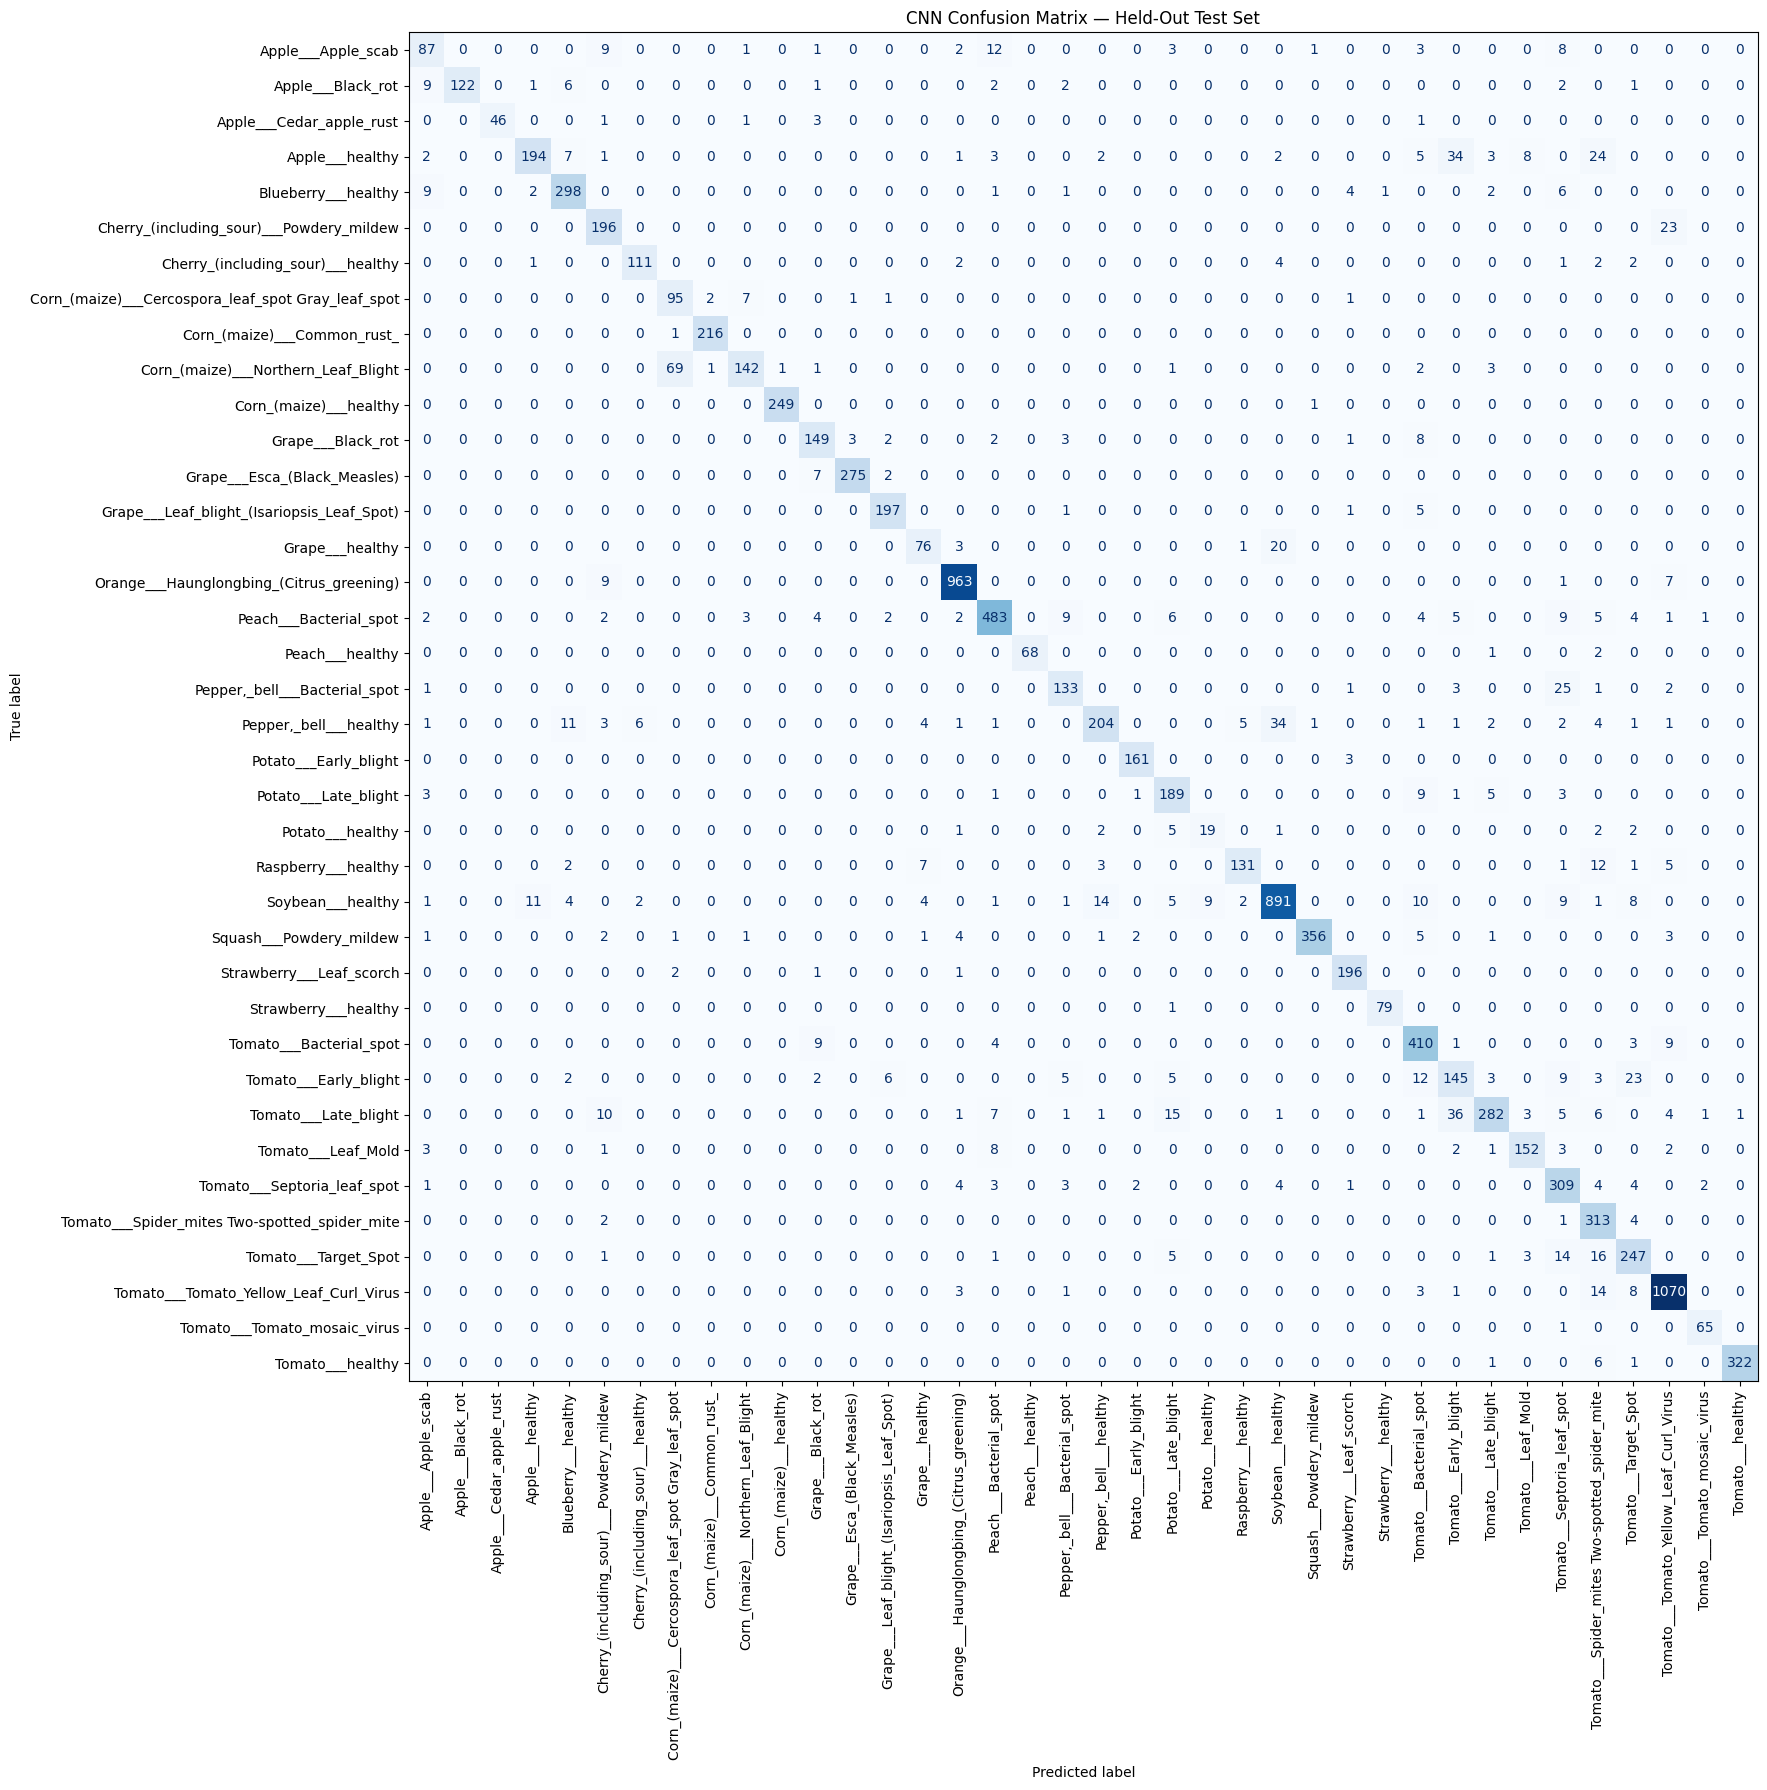

Confusion matrix saved to results/cnn_confusion_matrix.png


In [17]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(18, 18))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation="vertical",
    colorbar=False,
    values_format="d"
)

ax.set_title("CNN Confusion Matrix — Held-Out Test Set")
plt.tight_layout()

import os
os.makedirs("results", exist_ok=True)
plt.savefig(
    "results/cnn_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrix saved to results/cnn_confusion_matrix.png")


**CNN Error Analysis**

We examine some examples that are misclassified by the CNN on the held-out test set. In each example, the actual label is compared with the predicted label and the image of a leaf is displayed. This qualitative analysis allows to identify potential sources of error, e.g. similar disease symptoms, background differences, image quality limitation etc.

Misclassified images: 1068
Total test images: 10709


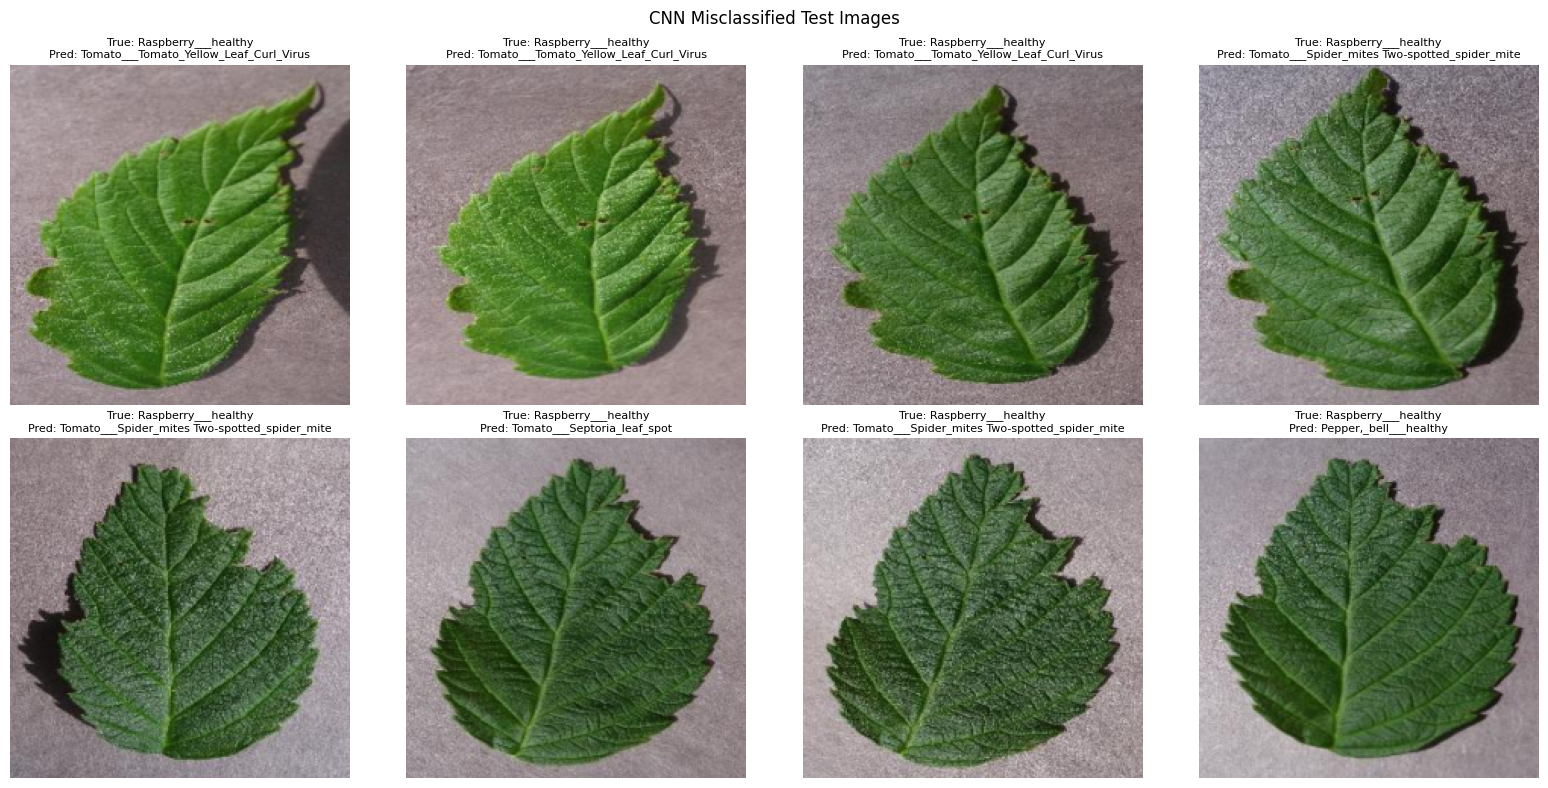

In [18]:

import matplotlib.pyplot as plt

# Collect indices of incorrect predictions
misclassified_indices = [
    i for i, (true_label, pred_label)
    in enumerate(zip(all_labels, all_predictions))
    if true_label != pred_label
]

print("Misclassified images:", len(misclassified_indices))
print("Total test images:", len(all_labels))

# Display up to 8 misclassified images
num_to_show = min(8, len(misclassified_indices))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, idx in zip(axes, misclassified_indices[:num_to_show]):
    image_tensor, true_label = test_loader.dataset[idx]

    # Undo ImageNet normalization for display
    image = image_tensor.cpu().clone()
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = image * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0).numpy()

    predicted_label = all_predictions[idx]

    ax.imshow(image)
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}",
        fontsize=8
    )
    ax.axis("off")

for ax in axes[num_to_show:]:
    ax.axis("off")

plt.suptitle("CNN Misclassified Test Images")
plt.tight_layout()
plt.savefig("results/cnn_misclassified_examples.png", dpi=150)
plt.show()
